In [ ]:
# Install quantum computing libraries
!pip install qiskit
!pip install qiskit-aer
!pip install pylatexenc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 9.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=0ef122450ca9ae6707f929fb9c7c5c49d6b3ccff4c1595d31d1aec7e2eeab95c
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.visualization import plot_histogram

In [ ]:
def create_oracle(n_qubits, target):

    oracle = QuantumCircuit(n_qubits)

    # Convert target to binary
    target_bin = format(target, '0' + str(n_qubits) + 'b')

    for i in range(n_qubits):
        if target_bin[i] == '0':
            oracle.x(i)

    oracle.h(n_qubits-1)
    oracle.mcx(list(range(n_qubits-1)), n_qubits-1)
    oracle.h(n_qubits-1)

    for i in range(n_qubits):
        if target_bin[i] == '0':
            oracle.x(i)

    return oracle

In [ ]:
def diffusion(n_qubits):

    diffuser = QuantumCircuit(n_qubits)

    diffuser.h(range(n_qubits))
    diffuser.x(range(n_qubits))

    diffuser.h(n_qubits-1)
    diffuser.mcx(list(range(n_qubits-1)), n_qubits-1)
    diffuser.h(n_qubits-1)

    diffuser.x(range(n_qubits))
    diffuser.h(range(n_qubits))

    return diffuser

In [ ]:


def grover_circuit(n_qubits, target):

    qc = QuantumCircuit(n_qubits, n_qubits)

    # Superposition
    qc.h(range(n_qubits))

    oracle = create_oracle(n_qubits, target)
    diffuser = diffusion(n_qubits)

    iterations = int(np.floor(np.pi/4 * np.sqrt(2**n_qubits)))

    for _ in range(iterations):
        qc.append(oracle.to_gate(), range(n_qubits))
        qc.append(diffuser.to_gate(), range(n_qubits))

    qc.measure(range(n_qubits), range(n_qubits))

    return qc

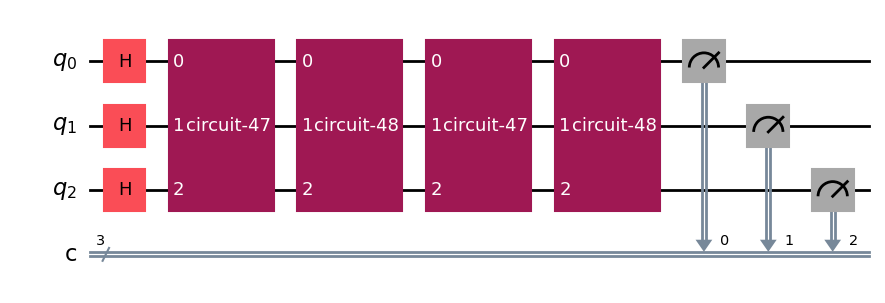

In [ ]:
n_qubits = 3
target_state = 5   # state we want to search

qc = grover_circuit(n_qubits, target_state)

qc.draw('mpl')

In [ ]:
simulator = Aer.get_backend('qasm_simulator')

compiled = transpile(qc, simulator)

result = simulator.run(compiled, shots=1024).result()

counts = result.get_counts()

print("Measurement Results:", counts)

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)


Measurement Results: {'100': 8, '001': 7, '110': 12, '010': 8, '000': 11, '011': 11, '111': 9, '101': 958}


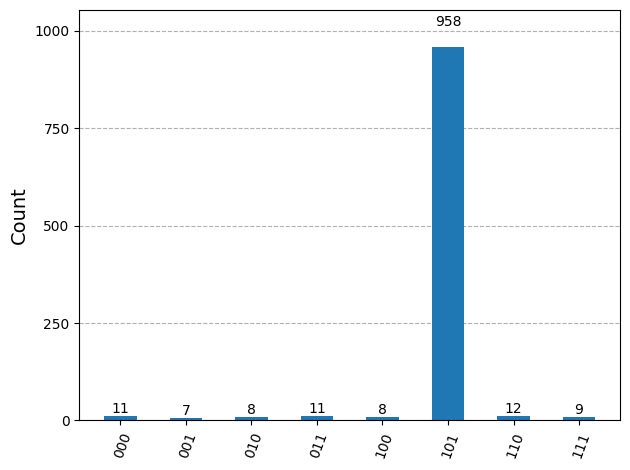

In [ ]:
plot_histogram(counts)

In [ ]:
def run_grover(n_qubits, target):

    qc = grover_circuit(n_qubits, target)

    simulator = Aer.get_backend('qasm_simulator')
    compiled = transpile(qc, simulator)

    result = simulator.run(compiled, shots=1024).result()
    counts = result.get_counts()

    print("Target State:", format(target, '0'+str(n_qubits)+'b'))

    display(qc.draw('mpl'))
    display(plot_histogram(counts))

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)


Target State: 110


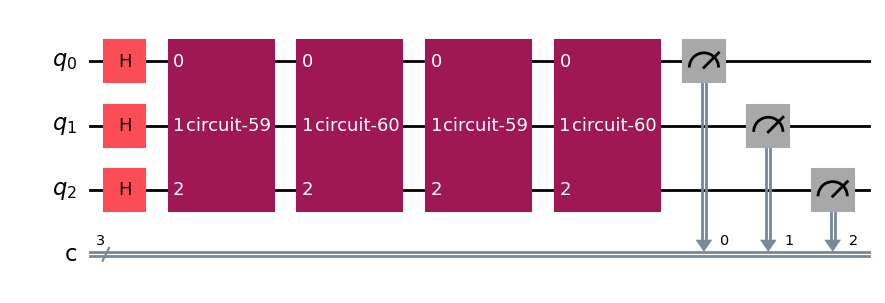

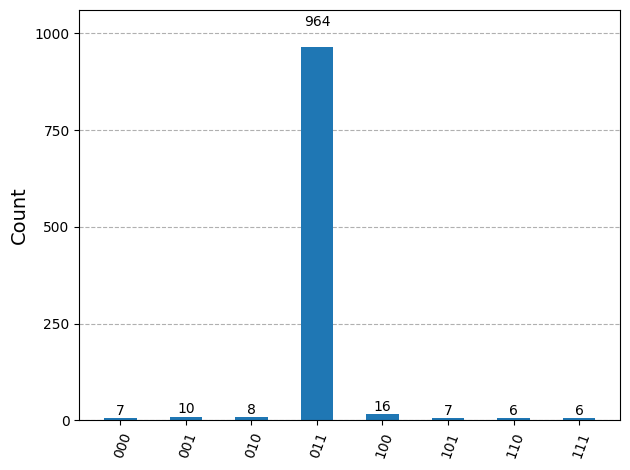

In [ ]:
run_grover(3,6)

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)


Target State: 10


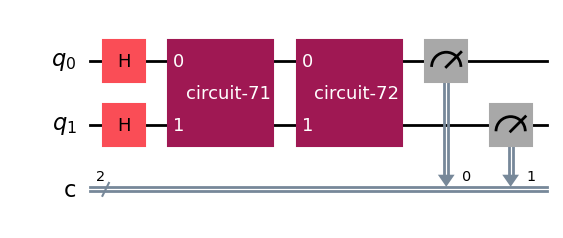

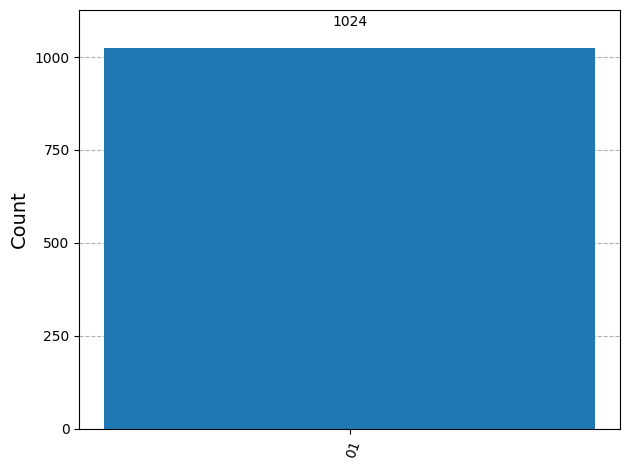

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)


Target State: 101


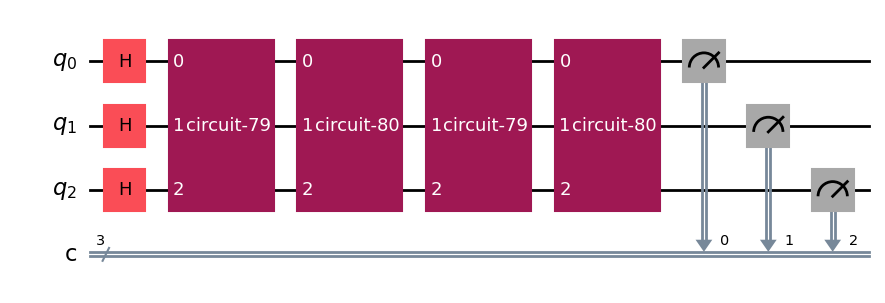

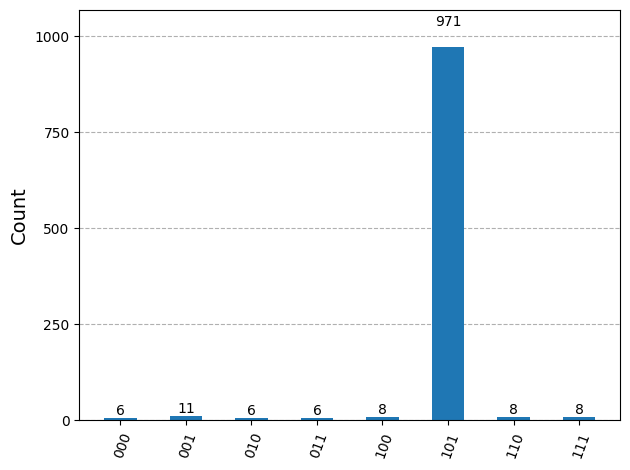

ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_backend': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)
ERROR:stevedore.extension:Could not load 'ibm_dynamic_circuits': cannot import name 'ProviderV1' from 'qiskit.providers' (/usr/local/lib/python3.12/dist-packages/qiskit/providers/__init__.py)


Target State: 1001


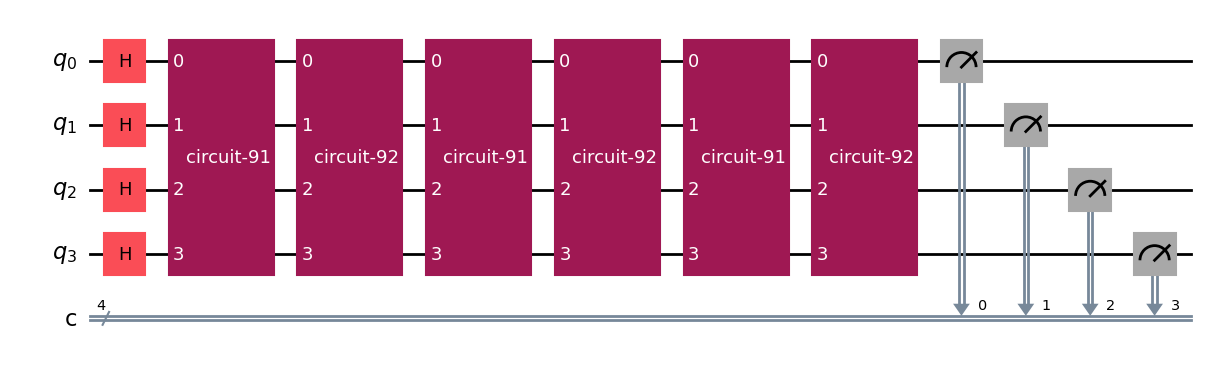

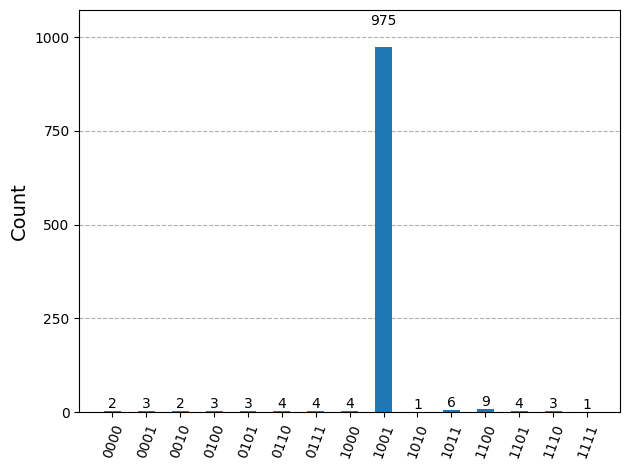

In [ ]:
run_grover(2,2)
run_grover(3,5)
run_grover(4,9)


In [ ]:
from qiskit.quantum_info import Statevector

n_qubits = 3

initial_state = Statevector.from_label('0'*n_qubits)

print("Initial State Vector:")
print(initial_state)

Initial State Vector:
Statevector([1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))


In [ ]:
from qiskit.quantum_info import Operator

qc_unitary = QuantumCircuit(2)
qc_unitary.h(0)
qc_unitary.cx(0,1)

unitary_matrix = Operator(qc_unitary)

print("Unitary Matrix of the Circuit:")
print(unitary_matrix.data)

Unitary Matrix of the Circuit:
[[ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j  0.        +0.j  0.        +0.j]]


In [ ]:
def oracle_matrix(n_qubits, target):

    size = 2**n_qubits
    matrix = np.identity(size)

    matrix[target][target] = -1

    return matrix


oracle = oracle_matrix(3,5)

print("Oracle Matrix:")
print(oracle)

Oracle Matrix:
[[ 1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  1.]]


In [ ]:
def diffusion_matrix(n_qubits):

    N = 2**n_qubits
    s = np.ones((N,N))/N

    D = 2*s - np.identity(N)

    return D


diff_matrix = diffusion_matrix(3)

print("Diffusion Matrix:")
print(diff_matrix)

Diffusion Matrix:
[[-0.75  0.25  0.25  0.25  0.25  0.25  0.25  0.25]
 [ 0.25 -0.75  0.25  0.25  0.25  0.25  0.25  0.25]
 [ 0.25  0.25 -0.75  0.25  0.25  0.25  0.25  0.25]
 [ 0.25  0.25  0.25 -0.75  0.25  0.25  0.25  0.25]
 [ 0.25  0.25  0.25  0.25 -0.75  0.25  0.25  0.25]
 [ 0.25  0.25  0.25  0.25  0.25 -0.75  0.25  0.25]
 [ 0.25  0.25  0.25  0.25  0.25  0.25 -0.75  0.25]
 [ 0.25  0.25  0.25  0.25  0.25  0.25  0.25 -0.75]]


In [ ]:
G = np.dot(diff_matrix, oracle)

print("Grover Operator Matrix:")
print(G)

Grover Operator Matrix:
[[-0.75  0.25  0.25  0.25  0.25 -0.25  0.25  0.25]
 [ 0.25 -0.75  0.25  0.25  0.25 -0.25  0.25  0.25]
 [ 0.25  0.25 -0.75  0.25  0.25 -0.25  0.25  0.25]
 [ 0.25  0.25  0.25 -0.75  0.25 -0.25  0.25  0.25]
 [ 0.25  0.25  0.25  0.25 -0.75 -0.25  0.25  0.25]
 [ 0.25  0.25  0.25  0.25  0.25  0.75  0.25  0.25]
 [ 0.25  0.25  0.25  0.25  0.25 -0.25 -0.75  0.25]
 [ 0.25  0.25  0.25  0.25  0.25 -0.25  0.25 -0.75]]


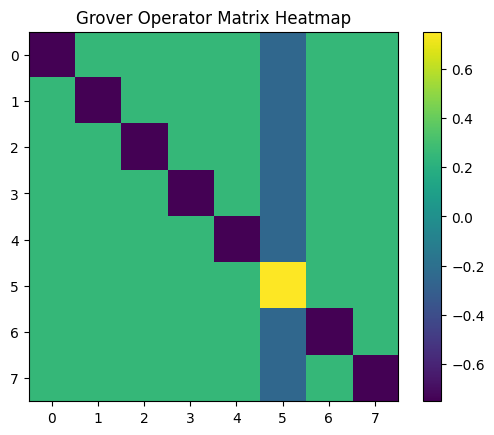

In [ ]:
plt.imshow(G, cmap='viridis')
plt.colorbar()
plt.title("Grover Operator Matrix Heatmap")
plt.show()

In [ ]:
state = np.ones(2**3)/np.sqrt(2**3)

print("Initial Superposition State:")
print(state)

state_after_oracle = np.dot(oracle, state)

print("\nAfter Oracle:")
print(state_after_oracle)

state_after_diffusion = np.dot(diff_matrix, state_after_oracle)

print("\nAfter Diffusion:")
print(state_after_diffusion)

Initial Superposition State:
[0.35355339 0.35355339 0.35355339 0.35355339 0.35355339 0.35355339
 0.35355339 0.35355339]

After Oracle:
[ 0.35355339  0.35355339  0.35355339  0.35355339  0.35355339 -0.35355339
  0.35355339  0.35355339]

After Diffusion:
[0.1767767  0.1767767  0.1767767  0.1767767  0.1767767  0.88388348
 0.1767767  0.1767767 ]
